## Challenge 4: Quantum Correlation Switch

### Part A — Correlated Outcomes

**Prediction:** Outcomes `00` and `11` will dominate, with approximately 50% probability each.

### Part B — Opposite Outcomes

**Prediction:** Outcomes `01` and `10` will dominate, with approximately 50% probability each.

### Comparison and Explanation

In Part A, the Hadamard and CNOT gates create a Bell state in which both qubits produce matching measurement results.

In Part B, an additional X gate is applied to qubit 1. This flips that qubit's state, changing the dominant outcomes from `00` and `11` to `01` and `10`.

The experiment demonstrates that adding a single quantum gate can change the correlation pattern between the measurement outcomes of two qubits.

### Conclusion

The two circuits demonstrate correlated and opposite measurement outcomes using two qubits and a small number of quantum gates.


Part A - Correlated
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
Measurement results: {'11': 49, '00': 51}
Total shots: 100


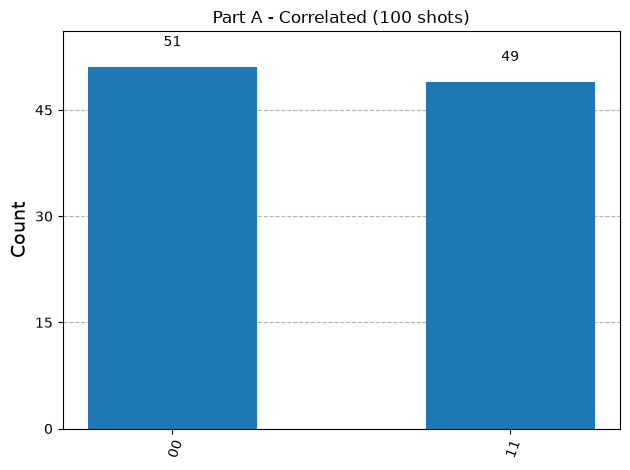


Part B - Opposite
     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 
Measurement results: {'01': 46, '10': 54}
Total shots: 100


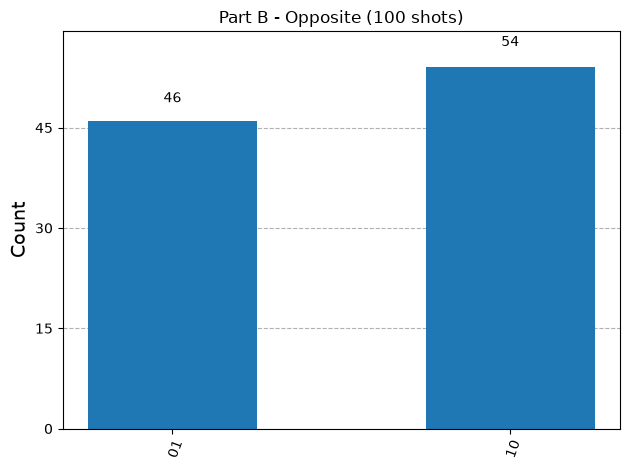

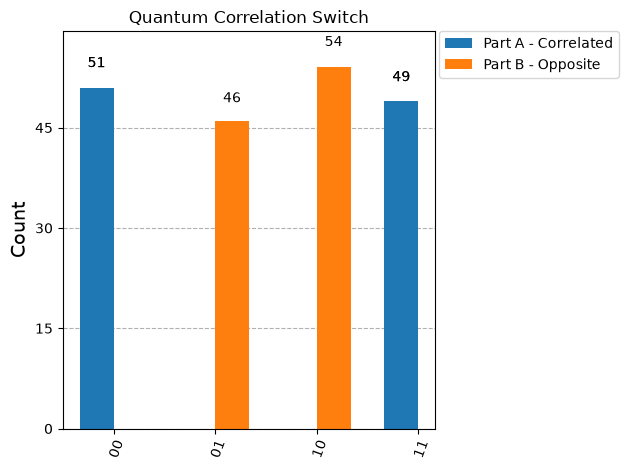

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display

simulator = AerSimulator()

# Part A: Correlated outcomes
circuit_a = QuantumCircuit(2, 2)
circuit_a.h(0)
circuit_a.cx(0, 1)
circuit_a.measure([0, 1], [0, 1])

# Part B: Opposite outcomes
circuit_b = QuantumCircuit(2, 2)
circuit_b.h(0)
circuit_b.cx(0, 1)
circuit_b.x(1)
circuit_b.measure([0, 1], [0, 1])

circuits = {
    "Part A - Correlated": circuit_a,
    "Part B - Opposite": circuit_b
}

results = {}

for name, circuit in circuits.items():
    result = simulator.run(circuit, shots=100).result()
    counts = result.get_counts()
    results[name] = dict(counts)

    print(f"\n{name}")
    print(circuit.draw(output="text"))
    print("Measurement results:", counts)
    print("Total shots:", sum(counts.values()))

    display(plot_histogram(
        counts,
        title=f"{name} (100 shots)"
    ))

# Compare both circuits
display(plot_histogram(
    list(results.values()),
    legend=list(results.keys()),
    title="Quantum Correlation Switch"
))

## Challenge 4: Quantum Correlation Switch

### Part A — Correlated Outcomes

**Actual results:**
- `00`: 51 measurements
- `11`: 49 measurements
- Total: 100 shots

The results show that both qubits produced matching outcomes.

### Part B — Opposite Outcomes

**Actual results:**
- `01`: 46 measurements
- `10`: 54 measurements
- Total: 100 shots

The results show that the qubits produced opposite outcomes.

### Comparison and Explanation

In Part A, the Hadamard and CNOT gates created a Bell state with correlated measurement outcomes. The dominant results were `00` and `11`.

In Part B, an X gate was added to qubit 1 after the CNOT gate. This flipped the second qubit, changing the dominant results to `01` and `10`.

The experiment demonstrates that adding one quantum gate can change the measurement correlation pattern of two entangled qubits.

### Conclusion

Both circuits successfully demonstrated correlated and opposite measurement outcomes using two qubits and a small number of quantum gates.